# Heart disease prediction: a tabular ML pipeline

**Question.** Given 13 routine clinical measurements, can we predict whether a patient has angiographic heart disease, and which measurements matter most?

**Data.** UCI *Heart Disease* (Cleveland clinic), 303 patients. Public domain, from the UCI ML Repository (id 45). The original target `num` is 0 (no disease) to 4 (severity); following the usual convention I treat any value above 0 as **disease**.

**Approach, in one line each**
1. Look at the data first (balance, missing values, distributions, correlations).
2. Build one leak-free `Pipeline` (imputation, encoding, scaling happen *inside* each cross-validation fold).
3. Add 4 engineered features and test honestly whether they help.
4. Compare 5 model families under the **same** repeated stratified 5-fold CV.
5. Tune the top 2 with **nested** CV, so the tuned score is not optimistically biased.
6. Explain the best model with permutation importance, and be clear about the limits (303 patients is small).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

SEED = 42
RES = Path("../results"); RES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette=["#0b6f8a", "#e4572e"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## 1. Load and inspect

In [2]:
raw = pd.read_csv("../data/uci_heart_raw.csv")
df = raw.copy()
df["target"] = (df["num"] > 0).astype(int)      # 1 = any heart disease
df = df.drop(columns="num")
print(df.shape)
display(df.head())
print("\nMissing values per column:"); print(df.isna().sum()[df.isna().sum() > 0])
print("\nTarget balance:"); print(df.target.value_counts().rename({0: "no disease", 1: "disease"}))

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Missing values per column:
ca      4
thal    2
dtype: int64

Target balance:
target
no disease    164
disease       139
Name: count, dtype: int64


Notes from the first look: 303 rows is **small**, so every number below carries real uncertainty and I report mean ± standard deviation across folds. The classes are roughly balanced (about 46% disease), so accuracy is meaningful, but I also track recall because in a screening setting a missed patient costs more than a false alarm. Only `ca` (4 rows) and `thal` (2 rows) have missing values, and they are the kind of missingness an imputer handles safely.

## 2. Exploratory analysis

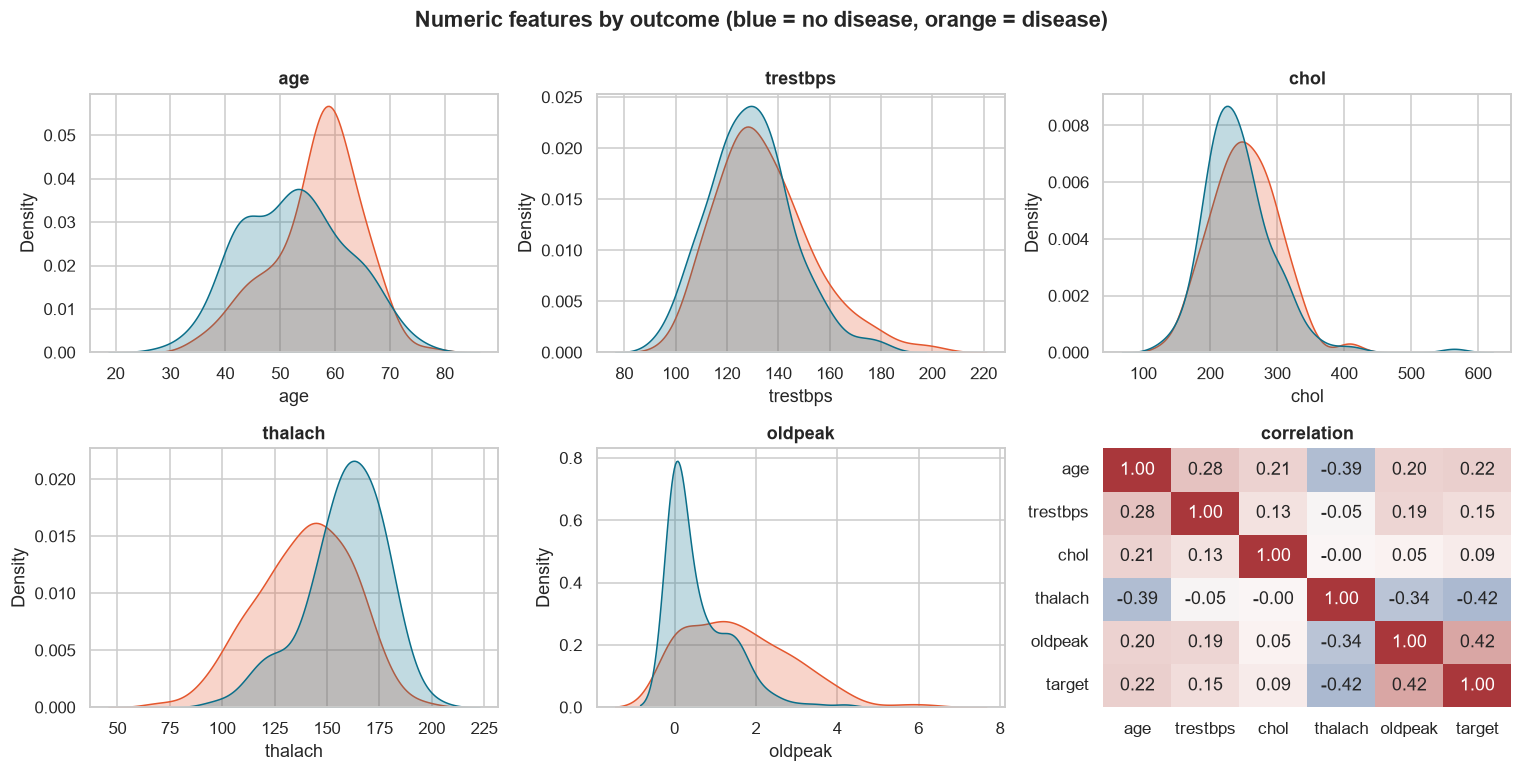

In [3]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), num_cols):
    sns.kdeplot(data=df, x=c, hue="target", fill=True, common_norm=False, ax=a, legend=False)
    a.set_title(c)
sns.heatmap(df[num_cols + ["target"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1, 2], cbar=False)
ax[1, 2].set_title("correlation")
fig.suptitle("Numeric features by outcome (blue = no disease, orange = disease)", y=1.0, fontweight="bold")
plt.tight_layout(); plt.savefig(RES / "eda_numeric.png", bbox_inches="tight"); plt.show()

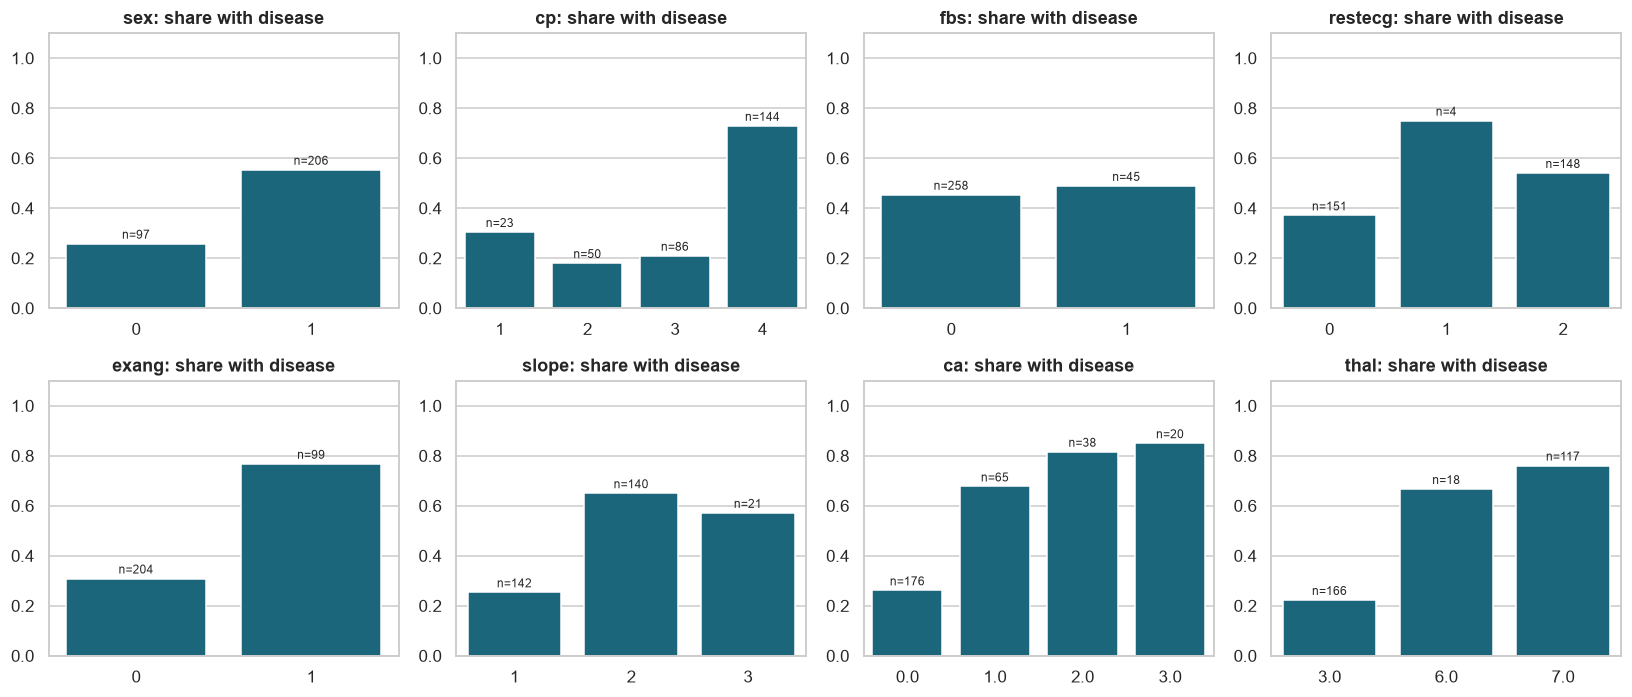

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(15, 6.5))
for a, c in zip(ax.ravel(), cat_cols):
    rate = df.groupby(c)["target"].agg(["mean", "size"])
    sns.barplot(x=rate.index.astype(str), y=rate["mean"], ax=a, color="#0b6f8a")
    for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
        a.text(i, m + 0.02, f"n={n}", ha="center", fontsize=8)
    a.set_title(f"{c}: share with disease"); a.set_ylim(0, 1.1); a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.savefig(RES / "eda_categorical.png", bbox_inches="tight"); plt.show()

**What the EDA suggests.** Maximum heart rate (`thalach`) is lower and ST depression (`oldpeak`) higher in patients with disease. Chest-pain type `cp = 4` (asymptomatic) has by far the highest disease rate, which is a known and slightly counter-intuitive finding in this dataset. Males, exercise-induced angina (`exang`), more blocked vessels (`ca`) and the reversible-defect thallium result (`thal = 7`) all raise the rate. Cholesterol and resting blood pressure separate the classes only weakly. These patterns tell me what to expect from the importance analysis later.

## 3. Preprocessing and feature engineering

Everything is one scikit-learn `Pipeline`, so imputation statistics, scaling and encoding are learned **only on the training part of each fold**. Fitting them on the full data first would leak information and flatter the scores.

Four engineered features, each with a reason:

| Feature | Definition | Why |
|---|---|---|
| `hr_reserve` | `thalach / (220 - age)` | Peak heart rate relative to the age-predicted maximum; a fitter heart reaches more of it |
| `st_depressed` | `oldpeak >= 1.0` | ST depression of 1 mm or more is the usual clinical threshold for ischaemia |
| `asymptomatic` | `cp == 4` | The strongest category in the EDA, made explicit for linear models |
| `chol_per_age` | `chol / age` | Cholesterol load relative to age |

I will test whether they actually help rather than assume it.

In [5]:
def add_features(X):
    X = X.copy()
    X["hr_reserve"] = X["thalach"] / (220 - X["age"])
    X["st_depressed"] = (X["oldpeak"] >= 1.0).astype(int)
    X["asymptomatic"] = (X["cp"] == 4).astype(int)
    X["chol_per_age"] = X["chol"] / X["age"]
    return X

ENG = ["hr_reserve", "st_depressed", "asymptomatic", "chol_per_age"]

def make_pre(engineered):
    num = num_cols + (["hr_reserve", "chol_per_age"] if engineered else [])
    cat = cat_cols + (["st_depressed", "asymptomatic"] if engineered else [])
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat),
    ])
    steps = ([("fe", FunctionTransformer(add_features))] if engineered else []) + [("pre", pre)]
    return steps

X = df.drop(columns="target"); y = df["target"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)   # the SAME folds for every model
print(f"{cv.get_n_splits()} train/test splits per model, identical for all models")

15 train/test splits per model, identical for all models


## 4. Model comparison under identical cross-validation

Five model families, all with the same preprocessing and the same 15 folds (5-fold × 3 repeats, stratified). I compare them with and without the engineered features.

In [6]:
MODELS = {
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "SVM (RBF)": SVC(probability=True, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2),
    "Gradient boosting": GradientBoostingClassifier(random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.9, eval_metric="logloss",
                             random_state=SEED, n_jobs=2),
}
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

def pipe(model, engineered):
    return Pipeline(make_pre(engineered) + [("clf", clone(model))])

def evaluate(est):
    r = cross_validate(est, X, y, cv=cv, scoring=SCORING, n_jobs=2)
    return {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in SCORING}

rows = []
for eng in (False, True):
    for name, m in MODELS.items():
        s = evaluate(pipe(m, eng))
        rows.append({"model": name, "engineered": eng, **{k: v for k, v in s.items()}})
res = pd.DataFrame(rows)

def fmt(t): return f"{t[0]:.3f} ± {t[1]:.3f}"
table = res.copy()
for m in SCORING: table[m] = table[m].map(fmt)
display(table[table.engineered].drop(columns="engineered").set_index("model"))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic regression,0.858 ± 0.052,0.877 ± 0.059,0.805 ± 0.096,0.837 ± 0.065,0.920 ± 0.038
SVM (RBF),0.839 ± 0.053,0.851 ± 0.062,0.789 ± 0.092,0.816 ± 0.067,0.906 ± 0.043
Random forest,0.838 ± 0.059,0.857 ± 0.058,0.777 ± 0.116,0.811 ± 0.080,0.912 ± 0.043
Gradient boosting,0.803 ± 0.037,0.811 ± 0.044,0.748 ± 0.087,0.775 ± 0.051,0.880 ± 0.046
XGBoost,0.827 ± 0.039,0.841 ± 0.055,0.777 ± 0.093,0.803 ± 0.051,0.897 ± 0.042


In [7]:
# Do the engineered features help? Compare mean ROC-AUC with vs without, per model.
cmp = res.pivot(index="model", columns="engineered", values="roc_auc").map(lambda t: t[0])
cmp.columns = ["AUC without", "AUC with engineered"]; cmp["change"] = cmp["AUC with engineered"] - cmp["AUC without"]
display(cmp.round(3))
print("Average change in AUC from the 4 engineered features: %+.4f" % cmp["change"].mean())

,AUC without,AUC with engineered,change
model,,,
Gradient boosting,0.878,0.880,0.002
Logistic regression,0.921,0.920,-0.001
Random forest,0.916,0.912,-0.004
SVM (RBF),0.905,0.906,0.001
XGBoost,0.895,0.897,0.002


Average change in AUC from the 4 engineered features: -0.0001


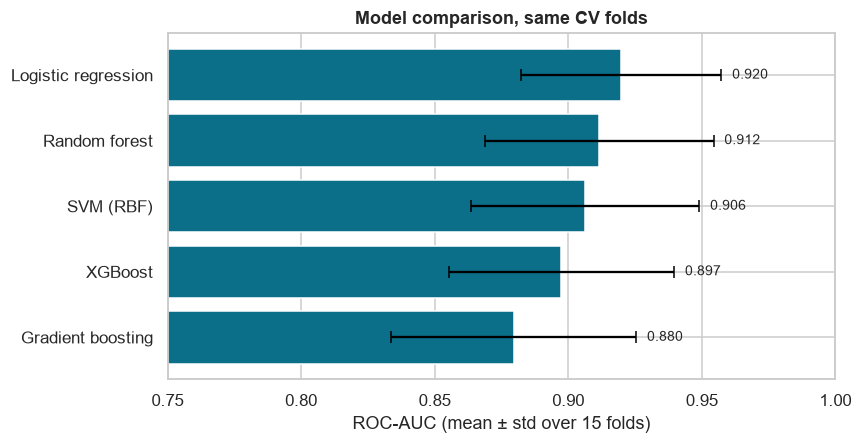

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = res[res.engineered].sort_values("roc_auc", key=lambda s: s.map(lambda t: t[0]))
ax.barh(d.model, d.roc_auc.map(lambda t: t[0]), xerr=d.roc_auc.map(lambda t: t[1]), color="#0b6f8a", capsize=4)
for i, t in enumerate(d.roc_auc): ax.text(t[0] + t[1] + 0.004, i, f"{t[0]:.3f}", va="center", fontsize=9)
ax.set_xlim(0.75, 1.0); ax.set_xlabel("ROC-AUC (mean ± std over 15 folds)"); ax.set_title("Model comparison, same CV folds")
plt.tight_layout(); plt.savefig(RES / "model_comparison.png", bbox_inches="tight"); plt.show()

## 5. Tune the top two models (nested cross-validation)

Picking hyper-parameters on the same folds you report on inflates the score. **Nested CV** fixes that: an inner 3-fold grid search picks parameters using only each outer training set, and the outer folds (the same 15 as before) score the result. The tuned number is therefore an honest estimate.

In [9]:
base = res[res.engineered].assign(auc=lambda d: d.roc_auc.map(lambda t: t[0])).sort_values("auc", ascending=False)
top2 = list(base.model.head(2)); print("Top 2 by untuned ROC-AUC:", top2)

GRIDS = {
    "Logistic regression": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "SVM (RBF)": {"clf__C": [0.3, 1, 3, 10], "clf__gamma": ["scale", 0.01, 0.03, 0.1]},
    "Random forest": {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 3, 5], "clf__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"clf__n_estimators": [50, 100, 200], "clf__max_depth": [2, 3], "clf__learning_rate": [0.03, 0.1]},
    "XGBoost": {"clf__n_estimators": [100, 200, 400], "clf__max_depth": [2, 3, 4], "clf__learning_rate": [0.02, 0.05, 0.1]},
}
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
tuned_scores, tuned_est = {}, {}
for name in top2:
    gs = GridSearchCV(pipe(MODELS[name], True), GRIDS[name], cv=inner, scoring="roc_auc", n_jobs=2)
    tuned_scores[name] = evaluate(gs)                 # nested: honest estimate
    tuned_est[name] = clone(gs).fit(X, y)             # refit on all data only to read the chosen parameters
    print(f"{name}: best params {tuned_est[name].best_params_}")

out = pd.DataFrame({
    "untuned AUC": {n: fmt(base.set_index('model').loc[n, 'roc_auc']) for n in top2},
    "tuned AUC (nested CV)": {n: fmt(tuned_scores[n]['roc_auc']) for n in top2},
    "tuned accuracy": {n: fmt(tuned_scores[n]['accuracy']) for n in top2},
    "tuned recall": {n: fmt(tuned_scores[n]['recall']) for n in top2},
    "tuned F1": {n: fmt(tuned_scores[n]['f1']) for n in top2},
})
display(out)

Top 2 by untuned ROC-AUC: ['Logistic regression', 'Random forest']


Logistic regression: best params {'clf__C': 0.3}


Random forest: best params {'clf__max_depth': 5, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}


,untuned AUC,tuned AUC (nested CV),tuned accuracy,tuned recall,tuned F1
Logistic regression,0.920 ± 0.038,0.919 ± 0.036,0.860 ± 0.049,0.803 ± 0.094,0.838 ± 0.063
Random forest,0.912 ± 0.043,0.910 ± 0.041,0.840 ± 0.056,0.765 ± 0.104,0.812 ± 0.073


## 6. Final model: out-of-fold performance and what drives it

Final model: Logistic regression


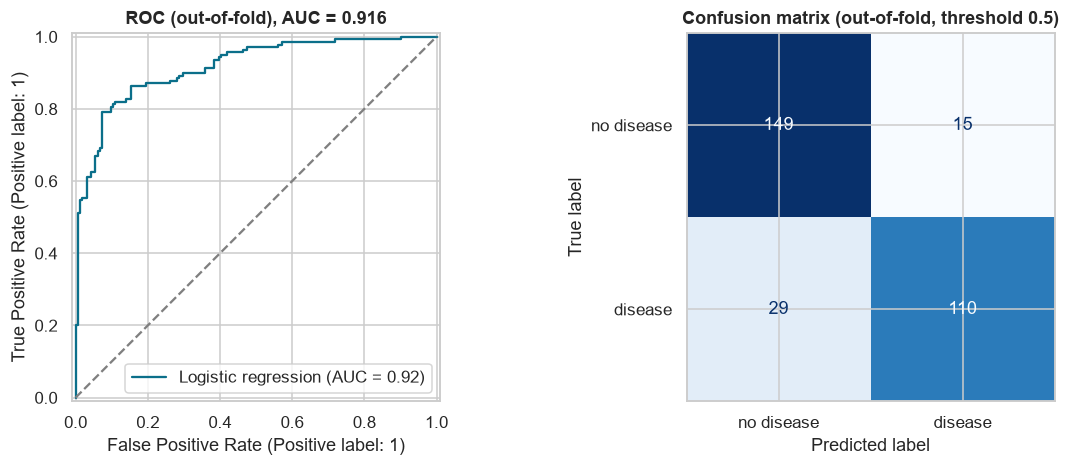

In [10]:
best = max(top2, key=lambda n: tuned_scores[n]["roc_auc"][0]); print("Final model:", best)
final = tuned_est[best].best_estimator_
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(clone(final), X, y, cv=skf, method="predict_proba")[:, 1]
pred = (oof >= 0.5).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
RocCurveDisplay.from_predictions(y, oof, ax=ax[0], name=best)
ax[0].plot([0, 1], [0, 1], "--", color="grey"); ax[0].set_title(f"ROC (out-of-fold), AUC = {roc_auc_score(y, oof):.3f}")
ConfusionMatrixDisplay.from_predictions(y, pred, ax=ax[1], cmap="Blues", display_labels=["no disease", "disease"], colorbar=False)
ax[1].set_title("Confusion matrix (out-of-fold, threshold 0.5)")
plt.tight_layout(); plt.savefig(RES / "final_model_roc_confusion.png", bbox_inches="tight"); plt.show()

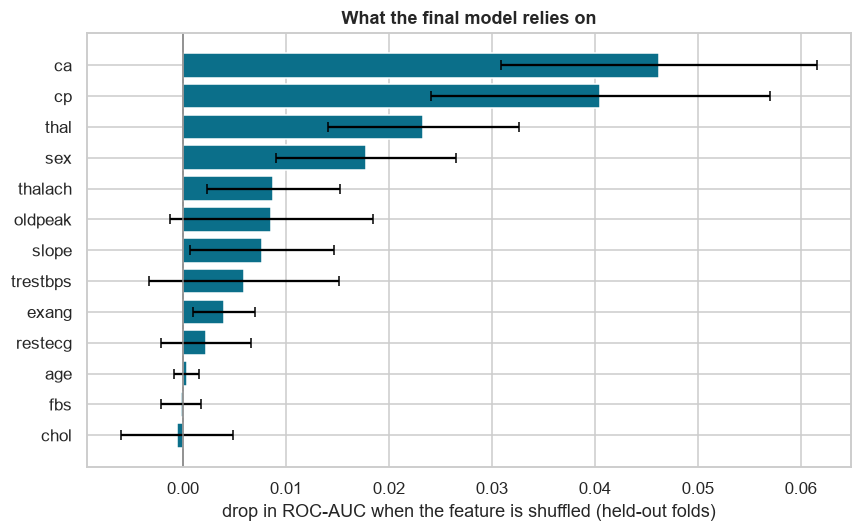

,mean,std
ca,0.0462,0.0153
cp,0.0405,0.0165
thal,0.0233,0.0093
sex,0.0178,0.0087
thalach,0.0088,0.0065
oldpeak,0.0086,0.0099
slope,0.0077,0.0070
trestbps,0.0059,0.0092


In [11]:
# Permutation importance, computed on held-out folds only, on the ORIGINAL columns (so one-hot pieces are not split apart).
imps = []
for tr, te in skf.split(X, y):
    m = clone(final).fit(X.iloc[tr], y.iloc[tr])
    r = permutation_importance(m, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=20, random_state=SEED)
    imps.append(pd.Series(r.importances_mean, index=X.columns))
imp = pd.concat(imps, axis=1)
imp_df = pd.DataFrame({"mean": imp.mean(axis=1), "std": imp.std(axis=1)}).sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_df.index, imp_df["mean"], xerr=imp_df["std"], color="#0b6f8a", capsize=3)
ax.axvline(0, color="grey", lw=1); ax.set_xlabel("drop in ROC-AUC when the feature is shuffled (held-out folds)")
ax.set_title("What the final model relies on")
plt.tight_layout(); plt.savefig(RES / "feature_importance.png", bbox_inches="tight"); plt.show()
display(imp_df.sort_values("mean", ascending=False).round(4).head(8))

In [12]:
summary = {
    "dataset": "UCI Heart Disease (Cleveland), 303 patients, target = any disease",
    "cv": "5-fold stratified x 3 repeats (15 splits), identical for every model",
    "comparison_with_engineered_features": {r.model: {k: [round(v[0], 4), round(v[1], 4)] for k, v in r._asdict().items() if k in SCORING}
                                              for r in res[res.engineered].itertuples()},
    "comparison_without_engineered_features": {r.model: {k: [round(v[0], 4), round(v[1], 4)] for k, v in r._asdict().items() if k in SCORING}
                                                 for r in res[~res.engineered].itertuples()},
    "engineered_feature_avg_auc_change": round(float(cmp["change"].mean()), 4),
    "tuned_nested_cv": {n: {k: [round(v[0], 4), round(v[1], 4)] for k, v in s.items()} for n, s in tuned_scores.items()},
    "best_params": {n: {k: (v if isinstance(v, (int, float, str)) or v is None else str(v)) for k, v in tuned_est[n].best_params_.items()} for n in top2},
    "final_model": best,
    "top_features": imp_df.sort_values("mean", ascending=False).head(6)["mean"].round(4).to_dict(),
}
Path("../results/metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps({k: summary[k] for k in ("final_model", "engineered_feature_avg_auc_change", "tuned_nested_cv", "top_features")}, indent=1))

{
 "final_model": "Logistic regression",
 "engineered_feature_avg_auc_change": -0.0001,
 "tuned_nested_cv": {
  "Logistic regression": {
   "accuracy": [
    0.8601,
    0.0491
   ],
   "precision": [
    0.8829,
    0.0534
   ],
   "recall": [
    0.8031,
    0.0939
   ],
   "f1": [
    0.8381,
    0.063
   ],
   "roc_auc": [
    0.9193,
    0.0357
   ]
  },
  "Random forest": {
   "accuracy": [
    0.8403,
    0.056
   ],
   "precision": [
    0.8739,
    0.0665
   ],
   "recall": [
    0.7649,
    0.1037
   ],
   "f1": [
    0.8118,
    0.0734
   ],
   "roc_auc": [
    0.9102,
    0.0406
   ]
  }
 },
 "top_features": {
  "ca": 0.0462,
  "cp": 0.0405,
  "thal": 0.0233,
  "sex": 0.0178,
  "thalach": 0.0088,
  "oldpeak": 0.0086
 }
}


## 7. Conclusions and limits

**What I found**
- **A simple model won.** Logistic regression had the best cross-validated ROC-AUC (**0.920 ± 0.038**), ahead of random forest (0.912), SVM (0.906), XGBoost (0.897) and gradient boosting (0.879). With 303 rows and mostly clinical categories, extra model capacity has little to learn from, and the linear model is also the easiest to explain.
- **Tuning did not help.** Under nested CV the tuned logistic regression scored 0.919 and the tuned random forest 0.910, no better than the defaults. The differences between the top models are smaller than the fold-to-fold spread (about 0.04), so I would not claim any of them is truly better than the others.
- **The 4 engineered features did not help either**: the average change in AUC was -0.0001. I kept the experiment in because a negative result is still a result; the signal in this dataset is already captured by the raw measurements.
- **What drives the prediction:** number of major vessels coloured by fluoroscopy (`ca`), chest-pain type (`cp`), the thallium test (`thal`) and sex. Age, fasting blood sugar and cholesterol add almost nothing once those are known, which matches the EDA.
- **Out-of-fold performance of the final model:** AUC 0.916, 110 of 139 diseased patients found (79% sensitivity) and 149 of 164 healthy patients cleared (91% specificity), at the default 0.5 threshold.

**Limits, stated plainly**
- 303 patients from one clinic is small; the intervals are wide and the model may not transfer to other populations.
- `ca` and `thal` come from invasive or specialist tests, so this is a study of what predicts angiographic disease, **not** a tool for screening someone from a routine check-up.
- The positive class merges all severity levels (1 to 4) into one.
- No external test set. Cross-validation is a good estimate here, but not a substitute for validation on a different hospital.
- Educational project, not medical advice.